#### **IMPORTS**

In [1]:
import spikeinterface as si
import numpy as np
import spikeinterface as si
from pathlib import Path
import matplotlib.pyplot as plt
import os

/u/gongt/conda-envs/spikeinterface/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
rec_dir = r'/ptmp/gongt/GLC6962_l_g1/preprocessed'
rec = si.load(rec_dir)
print(rec)

base_dir  = Path(rec_dir) / "thresholding_peaks"
peaks_path  = base_dir / "peaks_combined2_sorted.npy"
motion_path = base_dir / "motion_estimates" / "chunks_1" / "motion_dredge_0240min_0310min"

peaks  = np.load(peaks_path)
motion = si.Motion.load(motion_path)
print(f"Peaks: {len(peaks):,}  |  fields: {peaks.dtype.names}")

estimated_peak_locations = np.load('/ptmp/gongt/GLC6962_l_g1/preprocessed/thresholding_peaks/localized_peaks_mt_raw.npy')
print(f"Estimated peak locations shape: {estimated_peak_locations.shape}")
depths = estimated_peak_locations['y']

plot_start_time = 15200
plot_end_time = 15200+720

BinaryFolderRecording: 352 channels - 30.0kHz - 1 segments - 869,035,420 samples 
                       28,967.85s (8.05 hours) - float16 dtype - 569.78 GiB
Peaks: 111,965,320  |  fields: ('sample_index', 'channel_index', 'amplitude', 'segment_index', 'z')
Estimated peak locations shape: (111965320,)


In [3]:
time_offset = rec.get_times()[0]
print(time_offset)
print(rec.get_times()[-1])

297.57346666666666
29265.420766666666


#### **FUNCTIONS**

In [4]:
def plot_drift_scatter(peaks, depths, sampling_frequency, t_min=None, t_max=None, save_name=None):
    times = peaks['sample_index'] / sampling_frequency
    mask = np.ones(len(times), dtype=bool)
    if t_min is not None:
        mask &= times >= t_min
    if t_max is not None:
        mask &= times <= t_max
    
    times = times[mask]
    depths = depths[mask]
    
    plt.figure(figsize=(15, 15))
    plt.scatter(times, depths, s=1, color='k', alpha=0.01)
    plt.xlabel('Time (s)')
    plt.ylabel('Depth (um)')
    plt.title('Estimated Peak Depths Over Time')
    if save_name is not None:
        plt.savefig(save_name, dpi=150, bbox_inches='tight')
    plt.show()


In [5]:
def plot_motion_overlay(peaks, depths, motion_list, labels, colors, sampling_frequency,
                        start_time=None, end_time=None, time_offset=0, save_name=None):
    """Scatter of peak depths with drift lines overlaid.
    Each item in motion_list can be an si.Motion object or a dict with
    keys 'time_bins', 'depth_bins', 'dshift'.
    Drift lines cycle through distinct colours (each neighbouring window gets
    a different colour; colours repeat after one cycle).
    Multiple motion sources in motion_list are distinguished by linestyle.
    """
    DEPTH_COLORS = [
        'red', 'royalblue', 'darkgreen', 'darkorange', 'deeppink', 'saddlebrown', 'teal'
    ]

    plt.figure(figsize=(16, 16))

    peak_times = peaks['sample_index'] / sampling_frequency

    if start_time is None:
        start_time = peak_times.min()
    if end_time is None:
        end_time = peak_times.max()

    time_mask = (peak_times >= start_time) & (peak_times <= end_time)
    plt.scatter(peak_times[time_mask], depths[time_mask],
                s=1, color='k', alpha=0.01, label='Individual Spikes')

    linestyles = ['-', '--', ':', '-.']

    for m_idx, motion_src in enumerate(motion_list):
        label_base = labels[m_idx]
        ls = linestyles[m_idx % len(linestyles)]

        if isinstance(motion_src, dict):
            t_bins  = motion_src['time_bins']
            d_bins  = motion_src['depth_bins']
            dshift_ = motion_src['dshift']
        else:  # si.Motion
            t_bins  = motion_src.temporal_bins_s[0] - time_offset
            d_bins  = motion_src.spatial_bins_um
            dshift_ = motion_src.displacement[0]

        t_mask = (t_bins >= start_time) & (t_bins <= end_time)
        for i, start_depth in enumerate(d_bins):
            color = DEPTH_COLORS[i % len(DEPTH_COLORS)]  # cycle: each neighbour gets a different colour
            label = label_base if i == 0 else ""
            drift_line = start_depth + dshift_[:, i]
            plt.plot(t_bins[t_mask], drift_line[t_mask],
                     color=color, linewidth=1.2, alpha=0.8, label=label, linestyle=ls)

    plt.xlabel('Time (s)')
    plt.ylabel('Depth (um)')
    plt.title(f'Motion Estimation  [{start_time:.1f}s - {end_time:.1f}s]')
    plt.xlim(start_time, end_time)
    plt.legend(loc='upper right', markerscale=10)
    plt.grid(True, alpha=0.2)
    if save_name is not None:
        plt.savefig(save_name, dpi=150, bbox_inches='tight')
    plt.show()


In [6]:
def get_corrected_depths(peaks, depths, motion_src, sampling_frequency, time_offset=0):
    """Subtract motion shift from depths.
    motion_src can be an si.Motion object or a dict with keys 'time_bins', 'depth_bins', 'dshift'.
    """
    peak_times = peaks['sample_index'] / sampling_frequency
    if isinstance(motion_src, dict):
        t_bins  = motion_src['time_bins']
        d_bins  = motion_src['depth_bins']
        dshift_ = motion_src['dshift']
        # searchsorted: no large broadcast matrix, O(n log m)
        t_idx = np.clip(np.searchsorted(t_bins, peak_times) - 1, 0, len(t_bins) - 1)
        d_idx = np.clip(np.searchsorted(d_bins, depths)     - 1, 0, len(d_bins) - 1)
        shifts = dshift_[t_idx, d_idx]
    else:  # si.Motion
        shifts = motion_src.get_displacement_at_time_and_depth(
            peak_times + time_offset, depths
        )
    return depths - shifts

In [7]:
def get_channel_corrected_binned(peaks, channel_depths, motion_src, sampling_frequency,
                                  time_offset=0, bin_duration=10.0, smooth_sigma=0.0):
    """Non-rigid, time-binned channel correction.

    Non-rigid: each channel gets its own depth-dependent shift per time bin,
    matching DREDge's spatial_bins_um. Drift is evaluated at every channel's
    actual depth rather than at a single median depth.

    Parameters
    ----------
    bin_duration : float
        Width of time bins in seconds (default 10 s).
    smooth_sigma : float
        Sigma (in bins) for optional Gaussian smoothing of the drift matrix
        over the time axis before rounding. 0 = no smoothing (default).

    Returns
    -------
    corrected_channel : int array (n_peaks,)  -- corrected channel index
    bin_shifts_ref    : int array (n_bins,)   -- integer shift per bin at median depth (diagnostics)
    bin_centers       : float array (n_bins,) -- centre time of each bin
    """
    from scipy.ndimage import gaussian_filter1d

    peak_times = peaks['sample_index'] / sampling_frequency
    n_chan = len(channel_depths)

    sort_idx        = np.argsort(channel_depths)
    sorted_depths   = channel_depths[sort_idx]
    channel_spacing = float(np.median(np.diff(sorted_depths)))

    bin_edges   = np.arange(peak_times.min(), peak_times.max() + bin_duration, bin_duration)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    n_bins = len(bin_centers)

    # Build drift matrix: shape (n_chan, n_bins)
    # drift_matrix[ch, t] = displacement (um) at channel ch's depth at time bin t
    if isinstance(motion_src, dict):
        t_b     = motion_src['time_bins']
        d_b     = motion_src['depth_bins']
        dshift_ = motion_src['dshift']
        t_idx = np.clip(np.searchsorted(t_b, bin_centers)    - 1, 0, len(t_b) - 1)
        d_idx = np.clip(np.searchsorted(d_b, channel_depths) - 1, 0, len(d_b) - 1)
        drift_matrix = dshift_[np.ix_(t_idx, d_idx)].T   # (n_chan, n_bins)
    else:  # si.Motion -- vectorised over all (channel, bin) pairs
        ch_rep = np.repeat(channel_depths, n_bins)          # n_chan * n_bins
        t_rep  = np.tile(bin_centers + time_offset, n_chan)
        drift_matrix = motion_src.get_displacement_at_time_and_depth(
            t_rep, ch_rep
        ).reshape(n_chan, n_bins)

    if smooth_sigma > 0:
        drift_matrix = gaussian_filter1d(drift_matrix, sigma=smooth_sigma, axis=1)

    # Round drift to nearest integer number of channels  ->  (n_chan, n_bins)
    shifts_matrix = np.round(drift_matrix / channel_spacing).astype(int)

    # Each spike: look up its channel's shift at its time bin
    spike_bin       = np.clip(np.digitize(peak_times, bin_edges) - 1, 0, n_bins - 1)
    ch_idx          = peaks['channel_index']
    shift_per_spike = shifts_matrix[ch_idx, spike_bin]
    corrected_ch    = np.clip(ch_idx - shift_per_spike, 0, n_chan - 1)

    # Return median-channel bin shifts for diagnostics
    median_ch_idx  = np.argmin(np.abs(channel_depths - np.median(channel_depths)))
    bin_shifts_ref = shifts_matrix[median_ch_idx, :]

    return corrected_ch, bin_shifts_ref, bin_centers


def plot_channel_scatter(peaks, channel_idx, sampling_frequency, t_min=None, t_max=None,
                         save_name=None, title='Channel Index Over Time'):
    """Scatter plot of channel index (integer) vs time."""
    times = peaks['sample_index'] / sampling_frequency
    mask  = np.ones(len(times), dtype=bool)
    if t_min is not None:
        mask &= times >= t_min
    if t_max is not None:
        mask &= times <= t_max

    plt.figure(figsize=(15, 15))
    plt.scatter(times[mask], channel_idx[mask], s=1, color='k', alpha=0.01)
    plt.xlabel('Time (s)')
    plt.ylabel('Channel index')
    plt.title(title)
    if save_name is not None:
        plt.savefig(save_name, dpi=150, bbox_inches='tight')
    plt.show()


#### **LOCATIONS**

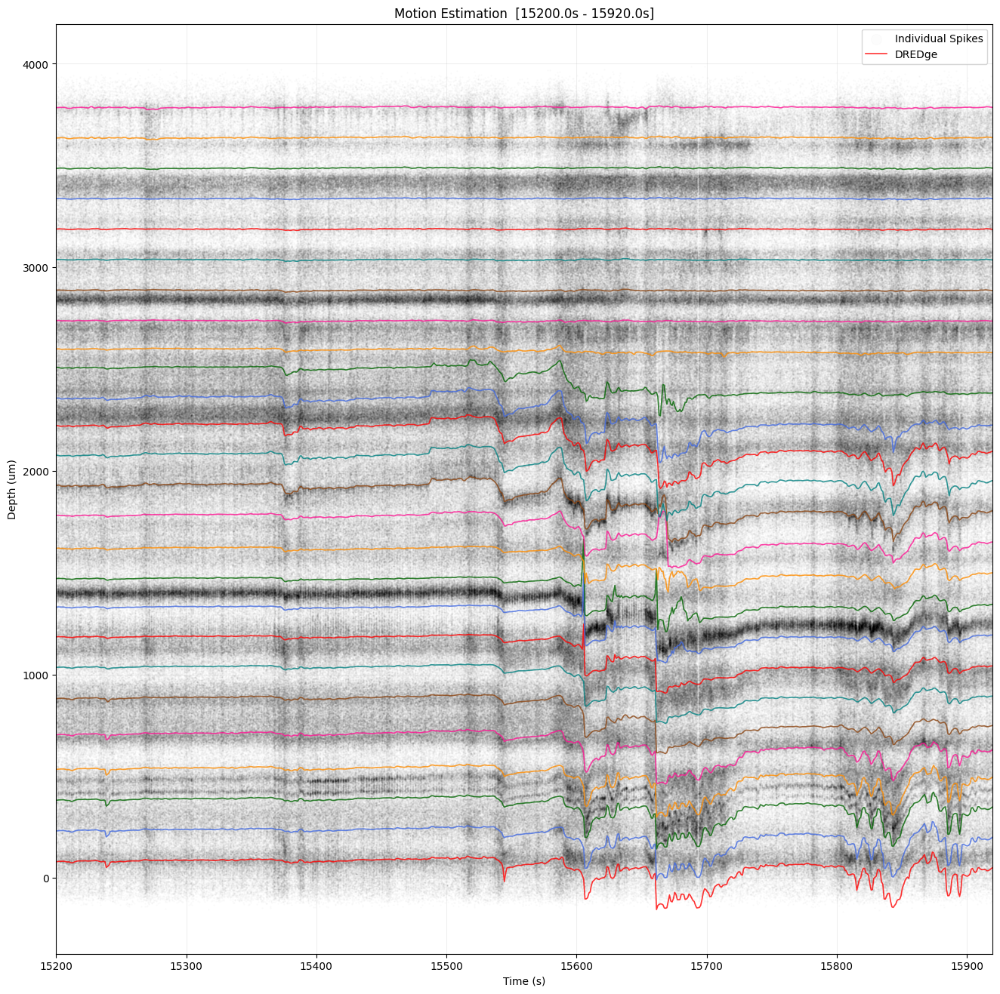

In [8]:
plot_motion_overlay(
    peaks,
    depths,
    motion_list=[motion],
    labels=['DREDge'],
    colors=['red'],
    sampling_frequency=rec.sampling_frequency,
    time_offset=time_offset,
    start_time=plot_start_time,
    end_time=plot_end_time,
    save_name=motion_path / f'motion_overlay_dredge_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png'
)


In [ ]:
corrected_depths = get_corrected_depths(
    peaks,
    depths,
    motion,
    rec.sampling_frequency,
    time_offset=time_offset
)

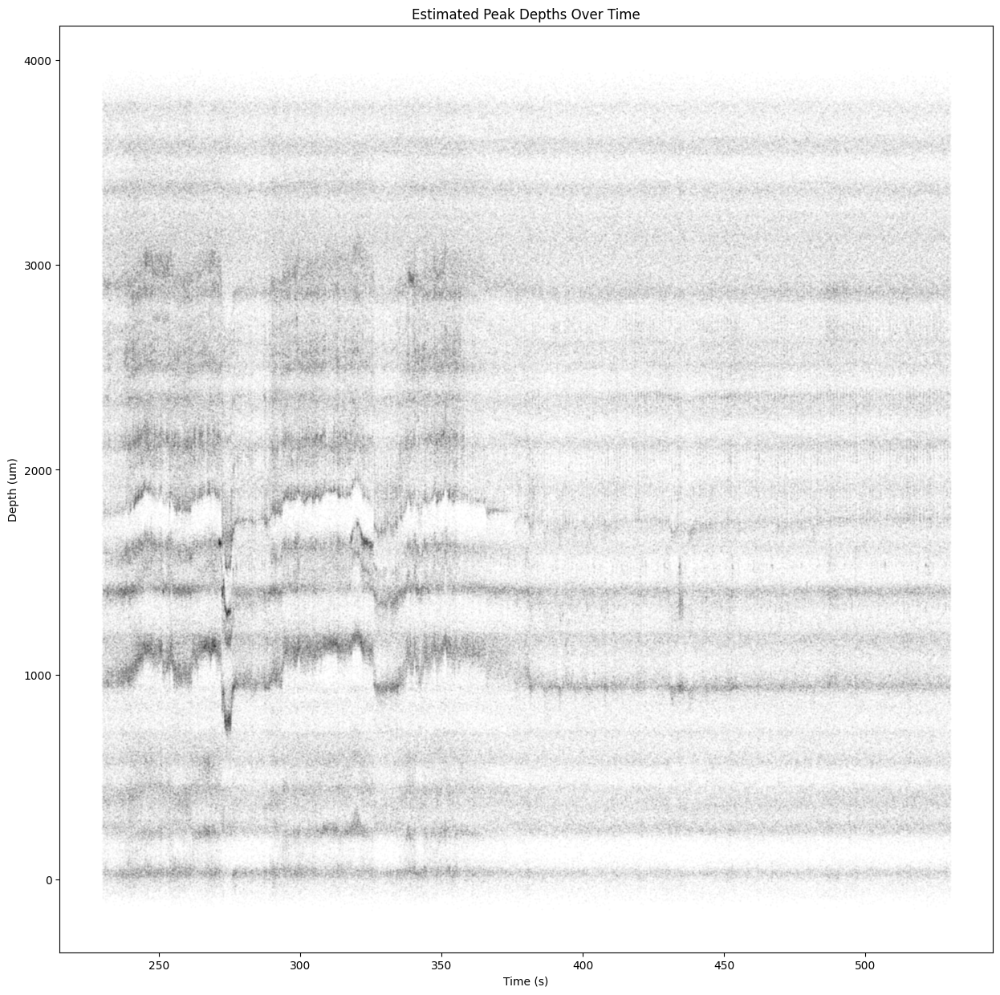

In [ ]:
plot_drift_scatter(peaks, depths, rec.sampling_frequency, t_min=plot_start_time, t_max=plot_end_time,
                   save_name=motion_path / f'drift_scatter_raw_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png')


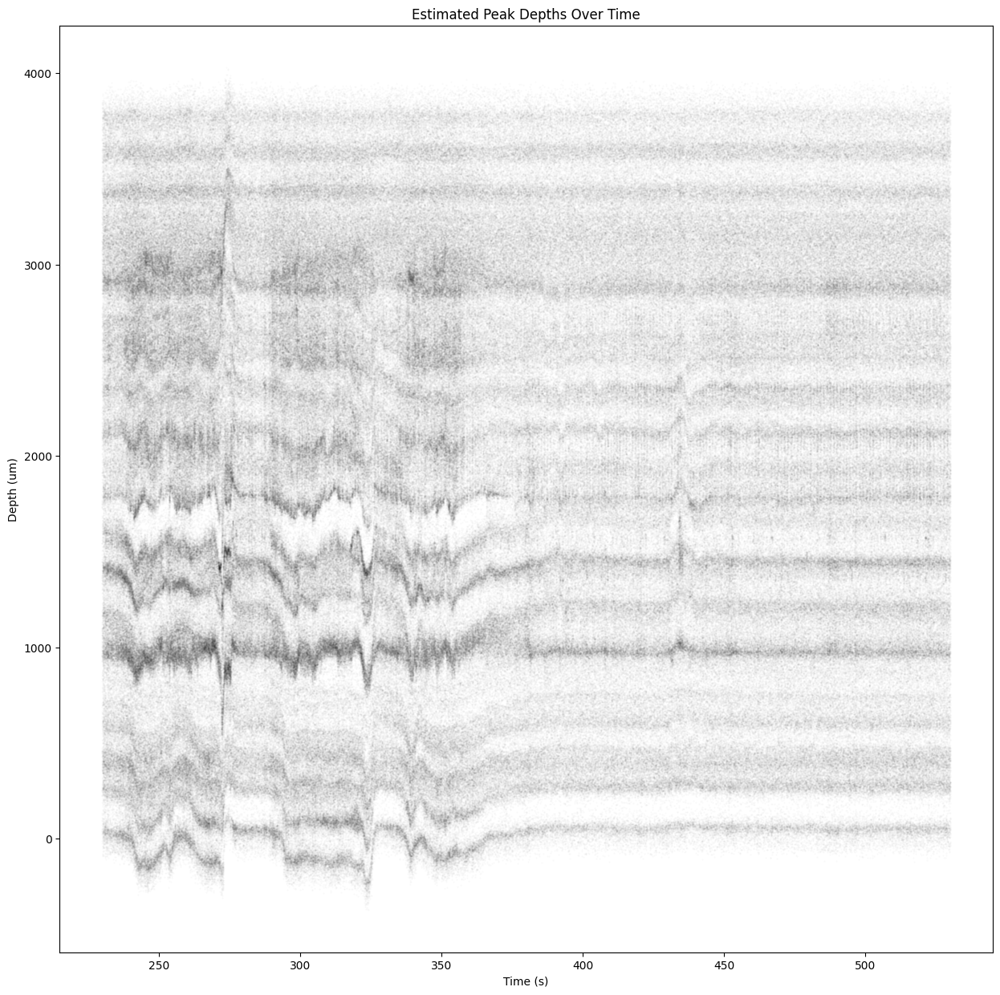

In [ ]:
plot_drift_scatter(peaks, corrected_depths, rec.sampling_frequency, t_min=plot_start_time, t_max=plot_end_time,
                   save_name=motion_path / f'drift_scatter_dredge_corrected_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png')


#### **CHANNELS**

In [ ]:
channel_positions = rec.get_channel_locations()   # (n_channels, 2)  col 0=x, col 1=y
channel_depths    = channel_positions[:, 1]        # y-coords in µm

depths2 = channel_depths[peaks["channel_index"]]     # depth of each peak's max channel

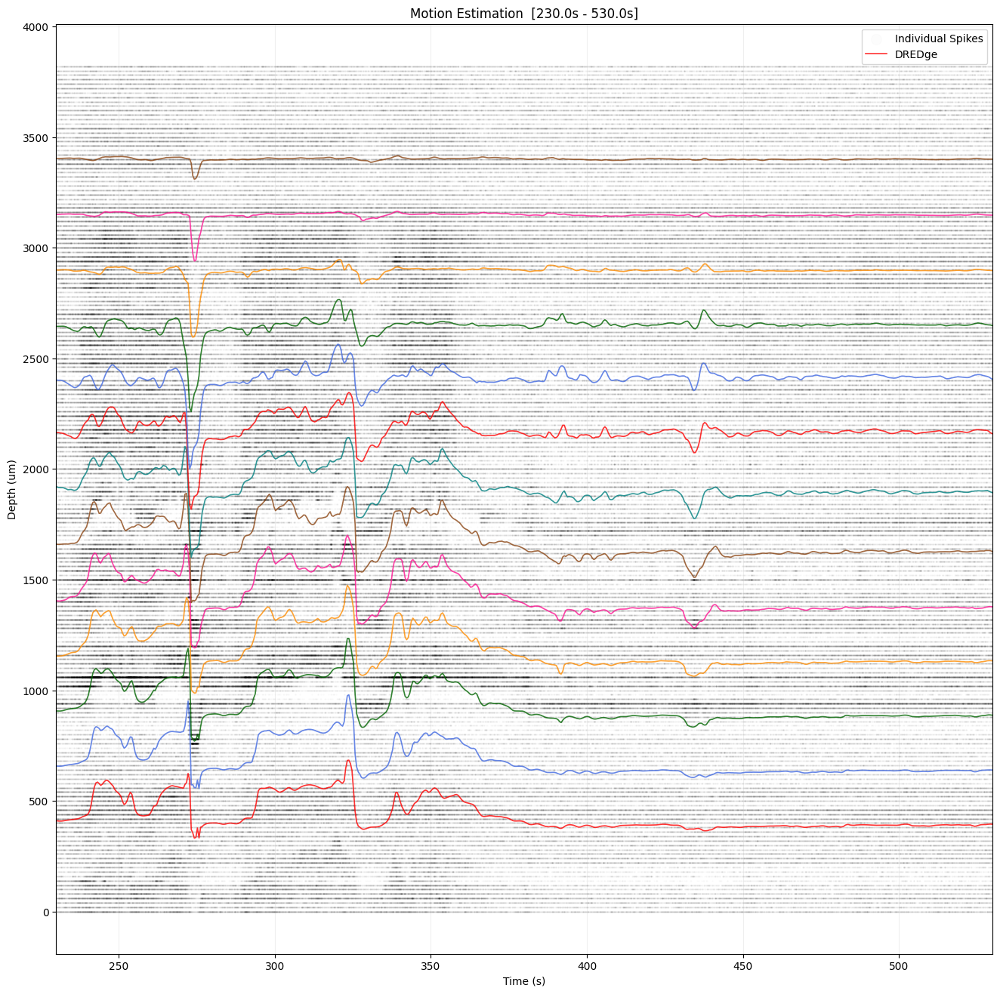

In [ ]:
plot_motion_overlay(
    peaks,
    depths2,
    motion_list=[motion],
    labels=['DREDge'],
    colors=['red'],
    sampling_frequency=rec.sampling_frequency,
    time_offset=time_offset,
    start_time=plot_start_time,
    end_time=plot_end_time,
    save_name=motion_path / f'motion_overlay_dredge_channels_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png'
)


In [ ]:
corrected_depths2 = get_corrected_depths(
    peaks,
    depths2,
    motion,
    rec.sampling_frequency,
    time_offset=time_offset
)

In [ ]:
sort_idx      = np.argsort(channel_depths)
sorted_depths = channel_depths[sort_idx]

ins  = np.searchsorted(sorted_depths, corrected_depths2)
ins  = np.clip(ins, 0, len(sorted_depths) - 1)
left = np.clip(ins - 1, 0, len(sorted_depths) - 1)
closer_left     = np.abs(corrected_depths2 - sorted_depths[left]) < np.abs(corrected_depths2 - sorted_depths[ins])
best_sorted_idx = np.where(closer_left, left, ins)

corrected_channel2        = sort_idx[best_sorted_idx]
corrected_depths2_snapped = channel_depths[corrected_channel2]

changed = corrected_channel2 != peaks['channel_index']
print(f'Peaks reassigned: {changed.sum():,} / {len(peaks):,}  ({100*changed.mean():.1f}%)')


Peaks reassigned: 92,994,409 / 126,258,007  (73.7%)


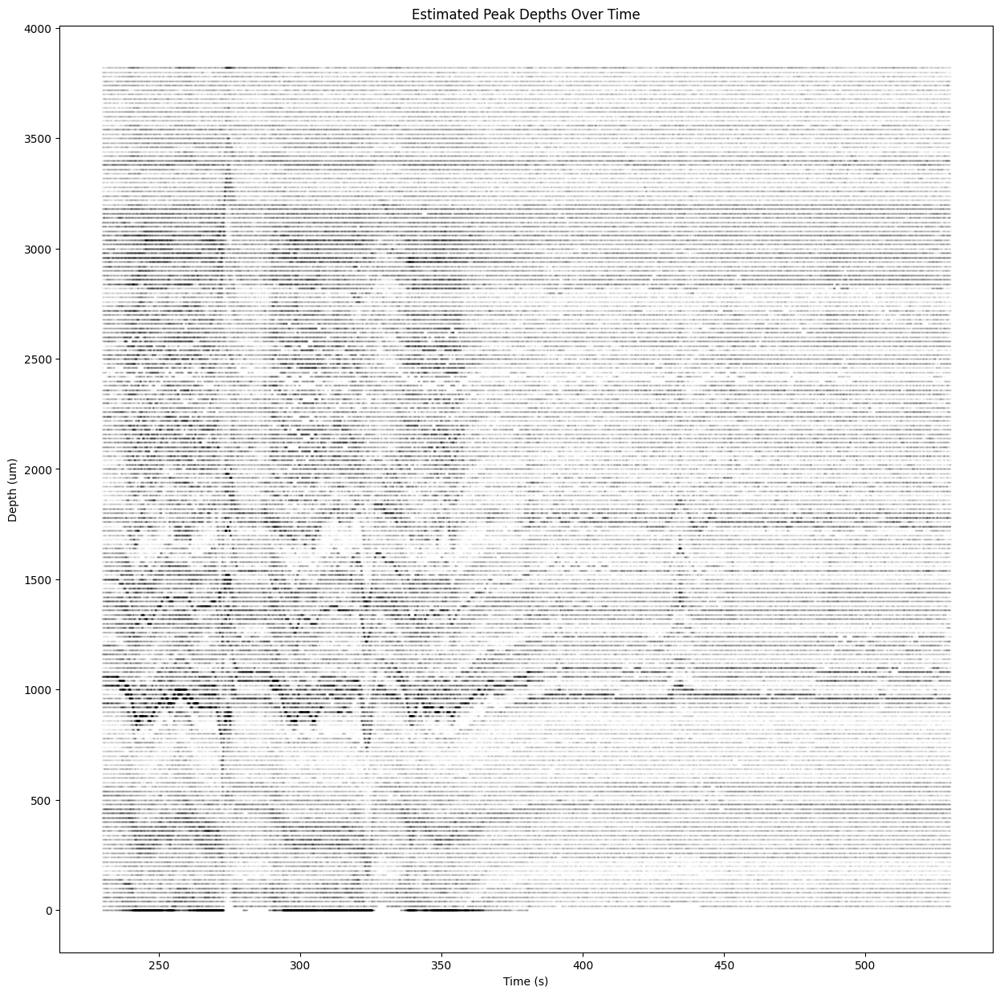

In [ ]:
plot_drift_scatter(peaks, corrected_depths2_snapped, rec.sampling_frequency, t_min=plot_start_time, t_max=plot_end_time,
                   save_name=motion_path / f'drift_scatter_dredge_channels_corrected_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png')


In [ ]:
# Binned channel correction: all spikes in each 10s window get the same integer
# channel shift, avoiding the per-spike boundary-flipping problem.
corrected_channel_binned, bin_shifts, bin_centers = get_channel_corrected_binned(
    peaks, channel_depths, motion, rec.sampling_frequency,
    time_offset=time_offset, bin_duration=10
)

changed_binned = corrected_channel_binned != peaks['channel_index']
ch_spacing = float(np.median(np.diff(np.sort(channel_depths))))
print(f'Channel spacing:          {ch_spacing:.1f} um')
print(f'Max integer shift:        {np.abs(bin_shifts).max()} channels')
print(f'Peaks reassigned (binned): {changed_binned.sum():,} / {len(peaks):,}  ({100*changed_binned.mean():.1f}%)')


Channel spacing:          20.0 um
Max integer shift:        13 channels
Peaks reassigned (binned): 60,170,697 / 126,258,007  (47.7%)


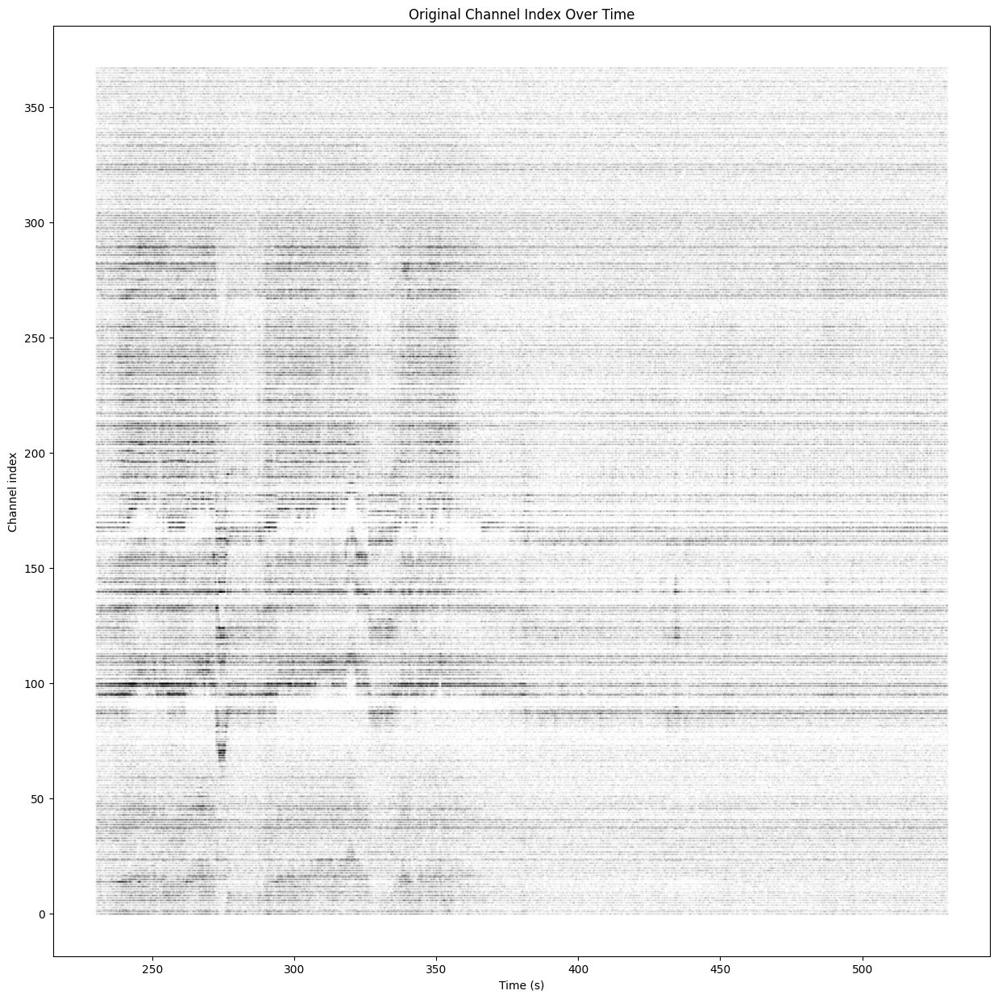

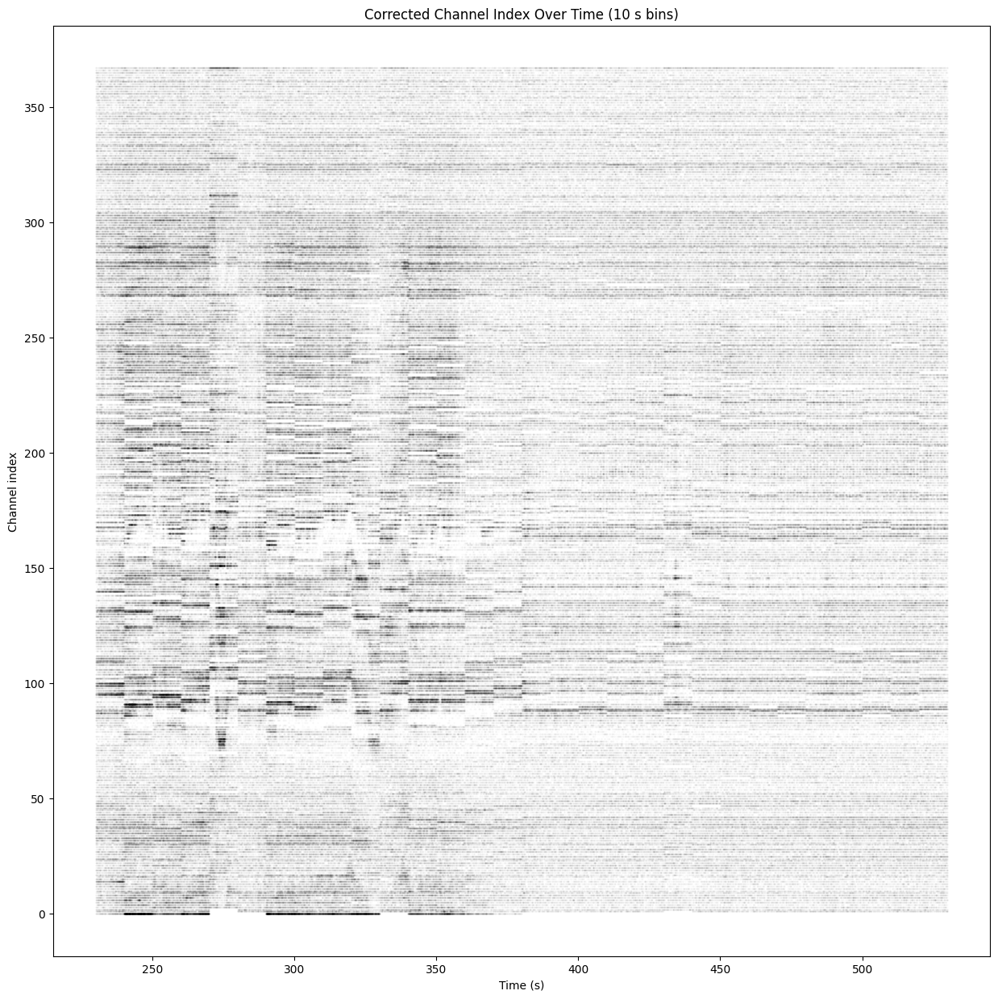

In [ ]:
# --- channel index scatter: shows discrete assignments directly ---
plot_channel_scatter(peaks, peaks['channel_index'], rec.sampling_frequency,
                     t_min=plot_start_time, t_max=plot_end_time,
                     save_name=motion_path / f'channel_scatter_raw_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png',
                     title='Original Channel Index Over Time')

plot_channel_scatter(peaks, corrected_channel_binned, rec.sampling_frequency,
                     t_min=plot_start_time, t_max=plot_end_time,
                     save_name=motion_path / f'channel_scatter_binned_corrected_{plot_start_time:.0f}s_{plot_end_time:.0f}s.png',
                     title='Corrected Channel Index Over Time (10 s bins)')


In [ ]:
# # Export for neural decoding
# out_dir = base_dir
# spike_times    = peaks["sample_index"].astype(np.int64)
# spike_clusters = corrected_channel.astype(np.int32)   # cluster id = motion-corrected channel

# np.save(out_dir / "spike_times.npy",    spike_times)
# np.save(out_dir / "spike_clusters.npy", spike_clusters)
# print(f"Saved spike_times ({spike_times.shape}) and spike_clusters ({spike_clusters.shape})")
# print(f"Unique clusters (channels): {np.unique(spike_clusters).size}")


#### **KS4 CORRECTION**

In [2]:
kilosort_output_dir = r'/ptmp/gongt/GLC6962_l_g1/KS4/test_MG_params2/sorter_output'
ops = np.load(os.path.join(kilosort_output_dir, 'ops.npy'), allow_pickle=True).item()
dshift = ops['dshift']                        # (n_batches, n_depth_bins)  shift in um
depth_bins_ks4 = ops['yblk']                  # (n_depth_bins,) depth in um
time_bins_ks4 = (np.arange(ops['Nbatches']) + 0.5) * ops['batch_size'] / ops['fs']  # batch centre times in s
print(f"dshift shape: {dshift.shape}")
print(f"time_bins range: {time_bins_ks4.min():.1f} – {time_bins_ks4.max():.1f} s")
print(f"depth_bins range: {depth_bins_ks4.min():.1f} – {depth_bins_ks4.max():.1f} um")

dshift shape: (14484, 1)
time_bins range: 1.0 – 28967.0 s
depth_bins range: 1909.0 – 1909.0 um


In [ ]:
# -- Build peaks + depths from KS4 sorter_output ---------------------------
# Compatible with SpikeInterface peaks structured array format so the rest of
# the notebook (plot_motion_overlay, get_corrected_depths, etc.) works unchanged.
_st   = np.load(os.path.join(kilosort_output_dir, 'spike_times.npy'))      # (N,) sample indices
_amp  = np.load(os.path.join(kilosort_output_dir, 'amplitudes.npy'))       # (N,) amplitudes
_spos = np.load(os.path.join(kilosort_output_dir, 'spike_positions.npy'))  # (N, 2): [x, y] um
_tmpl = np.load(os.path.join(kilosort_output_dir, 'spike_templates.npy'))  # (N,) template idx
_tind = np.load(os.path.join(kilosort_output_dir, 'templates_ind.npy'))    # (n_templates, n_ch): col0 = best ch

peaks = np.zeros(len(_st), dtype=[('sample_index',  '<i8'),
                                   ('channel_index', '<i8'),
                                   ('amplitude',     '<f8'),
                                   ('segment_index', '<i8')])
peaks['sample_index']  = _st.astype(np.int64)
peaks['channel_index'] = _tind[_tmpl, 0].astype(np.int64)  # best channel per template
peaks['amplitude']     = _amp.astype(np.float64)
peaks['segment_index'] = 0

depths = _spos[:, 1].astype(np.float64)   # y-coord from KS4 spike positions = depth in um

print(f'KS4 peaks : {len(peaks):,}')
print(f'  sample_index : {peaks["sample_index"].min():,} - {peaks["sample_index"].max():,}  '
      f'({peaks["sample_index"].max() / ops["fs"]:.1f} s @ {ops["fs"]:.1f} Hz)')
print(f'  channel_index: {peaks["channel_index"].min()} - {peaks["channel_index"].max()}')
print(f'  amplitude    : {np.abs(peaks["amplitude"]).min():.2f} - {np.abs(peaks["amplitude"]).max():.2f}')
print(f'  depths       : {depths.min():.1f} - {depths.max():.1f} um')

In [5]:
plot_motion_overlay(
    peaks,
    depths,
    motion_list=[{"time_bins": time_bins_ks4, "depth_bins": depth_bins_ks4, "dshift": -dshift}],
    labels=['KS4'],
    colors=['red'],
    sampling_frequency=rec.sampling_frequency,
    start_time=2400,
    end_time=2450,
    save_name=motion_path / 'motion_overlay_ks4_2400_2450.png'
)


NameError: name 'peaks' is not defined

In [ ]:
# ks4_corrected_depths = get_corrected_depths(
#     peaks,
#     depths,
#     {"time_bins": time_bins_ks4, "depth_bins": depth_bins_ks4, "dshift": -dshift},
#     rec.sampling_frequency
# )

In [ ]:
# plot_drift_scatter(peaks, ks4_corrected_depths, rec.sampling_frequency, t_min=0*60, t_max=15*60,
#                    save_name=motion_path / 'drift_scatter_ks4_corrected.png')


#### **JITTER DIAGNOSTICS — chunks_n21 / amp20pc**

Checks whether jitter in the DREDge motion trace is real or an artifact of:
- too few spikes in a window → unreliable pairwise correlation
- no coherent displacement in a window → flat/noisy histogram
- specific depth ranges or time periods

Three hypotheses tested:
1. **Low spike count** → displacement estimate is noise-driven
2. **High local displacement variance** → jitter regardless of spike count
3. **Spectral analysis** → broadband noise vs. genuine sharp events

In [6]:

# ── Cell J1: load motion + filter peaks to chunk time range ──────────────────
import json

CHUNKS_DIR  = "chunks_n25"
MOTION_NAME = "motion_dredge_amp20pct_0000min_0070min"

motion_path_j = base_dir / "motion_estimates" / CHUNKS_DIR / MOTION_NAME

with open(motion_path_j.parent / "motion_params.json") as f:
    mparams = json.load(f)

dparams  = mparams["dredge_params"]
win_step = dparams["win_step_um"]
win_scale= dparams["win_scale_um"]
bin_s_j  = dparams["bin_s"]
amp_pct_j= mparams["amp_percentile"]

displacement_j = np.load(motion_path_j / "displacement_seg0.npy")   # (n_t, n_win)
t_bins_abs     = np.load(motion_path_j / "temporal_bins_s_seg0.npy") # absolute times
s_bins_j       = np.load(motion_path_j / "spatial_bins_um.npy")      # (n_win,)

t_bins_rel_j = t_bins_abs - time_offset   # → recording-relative times
n_t_j, n_win_j = displacement_j.shape

print(f"Displacement: {displacement_j.shape}  (n_time_bins={n_t_j}, n_windows={n_win_j})")
print(f"Time range (rec-relative): {t_bins_rel_j[0]:.1f} – {t_bins_rel_j[-1]:.1f} s  (bin_s={bin_s_j})")
print(f"Window centres (µm): {s_bins_j}")
print(f"win_step={win_step} µm  win_scale={win_scale} µm  win_shape={dparams.get('win_shape','gaussian')}")

# Filter peaks to chunk time window + amplitude threshold
peak_times_s = peaks['sample_index'] / rec.sampling_frequency
amp_thr_j    = np.percentile(np.abs(peaks['amplitude']), amp_pct_j)
amp_mask_j   = np.abs(peaks['amplitude']) >= amp_thr_j

chunk_mask = amp_mask_j & (peak_times_s >= t_bins_rel_j[0]) & (peak_times_s <= t_bins_rel_j[-1])
pt_j = peak_times_s[chunk_mask]
pd_j = estimated_peak_locations['y'][chunk_mask]
print(f"\nPeaks in chunk + amp>={amp_pct_j}th pct: {chunk_mask.sum():,}")


DIAG_SAVE_DIR = motion_path_j / "diagnostic_plots"
DIAG_SAVE_DIR.mkdir(exist_ok=True)
print(f"Diagnostic plots → {DIAG_SAVE_DIR}")


Displacement: (4200, 24)  (n_time_bins=4200, n_windows=24)
Time range (rec-relative): 0.5 – 4199.5 s  (bin_s=1)
Window centres (µm): [ 185.  335.  485.  635.  785.  935. 1085. 1235. 1385. 1535. 1685. 1835.
 1985. 2135. 2285. 2435. 2585. 2735. 2885. 3035. 3185. 3335. 3485. 3635.]
win_step=150 µm  win_scale=300 µm  win_shape=gaussian

Peaks in chunk + amp>=20th pct: 13,627,601
Diagnostic plots → /ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed/thresholding_peaks_3.3/motion_estimates/chunks_n25/motion_dredge_amp20pct_0000min_0070min/diagnostic_plots


In [7]:

# ── Cell J2: spike count per (time_bin, window) ───────────────────────────────
# DREDge rect window: each window covers [center - win_scale/2, center + win_scale/2]
half_win_j = win_scale / 2.0
t_edges_j  = np.append(t_bins_rel_j - bin_s_j / 2, t_bins_rel_j[-1] + bin_s_j / 2)

spike_counts_j = np.zeros((n_t_j, n_win_j), dtype=np.int32)
for w, wc in enumerate(s_bins_j):
    in_win = (pd_j >= wc - half_win_j) & (pd_j <= wc + half_win_j)
    spike_counts_j[:, w], _ = np.histogram(pt_j[in_win], bins=t_edges_j)

n_cells = spike_counts_j.size
print(f"Spike counts per (time_bin, window):  total cells = {n_cells:,}")
print(f"  min    : {spike_counts_j.min()}")
print(f"  max    : {spike_counts_j.max()}")
print(f"  median : {np.median(spike_counts_j):.0f}")
print(f"  mean   : {spike_counts_j.mean():.1f}")
n_lt10 = (spike_counts_j < 10).sum()
n_eq0  = (spike_counts_j == 0).sum()
print(f"  count < 10 spikes : {n_lt10:6d}  ({100*n_lt10/n_cells:.3f}%)")
print(f"  count = 0  spikes : {n_eq0:6d}  ({100*n_eq0/n_cells:.3f}%)")


Spike counts per (time_bin, window):  total cells = 100,800
  min    : 0
  max    : 1066
  median : 244
  mean   : 257.4
  count < 10 spikes :     24  (0.024%)
  count = 0  spikes :     24  (0.024%)


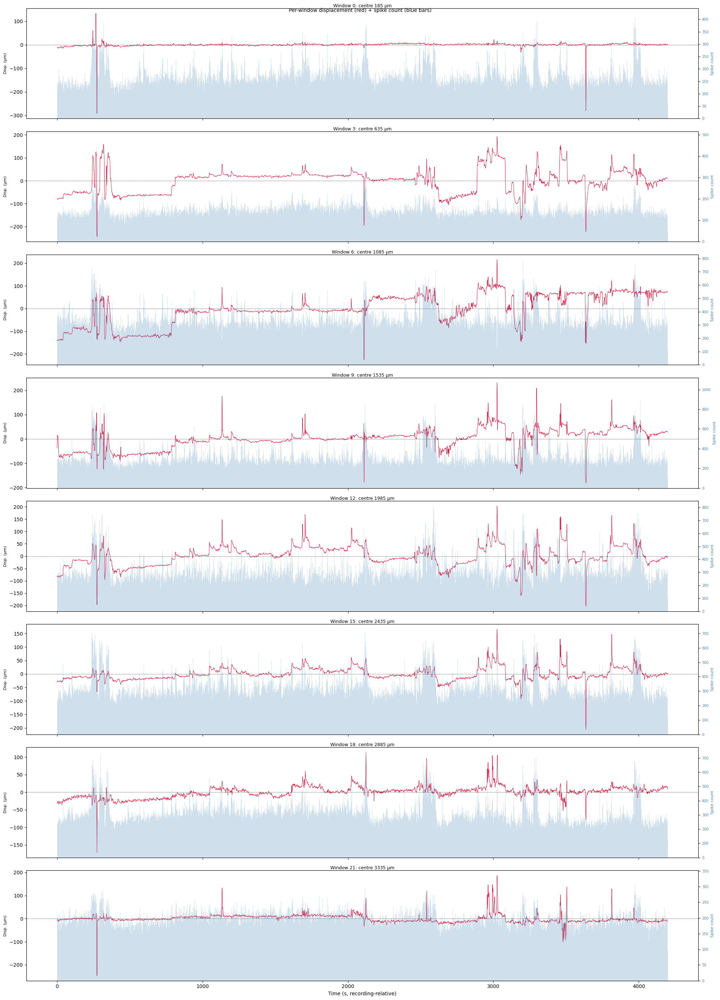

In [8]:
# ── Cell J4: per-window displacement trace + spike count bar ──────────────────
# Look at individual windows to spot which ones jitter and whether spike count is low
WIN_SUBSET = list(range(0, n_win_j, max(1, n_win_j // 8)))  # ~8 evenly-spaced windows
# ↑ override manually: e.g. WIN_SUBSET = [3, 8, 12, 18]

fig, axes = plt.subplots(len(WIN_SUBSET), 1, figsize=(20, 3.5 * len(WIN_SUBSET)), sharex=True)
if len(WIN_SUBSET) == 1:
    axes = [axes]

for ax, w in zip(axes, WIN_SUBSET):
    ax2 = ax.twinx()
    ax2.bar(t_bins_rel_j, spike_counts_j[:, w], width=bin_s_j,
            color='steelblue', alpha=0.25, label='spike count')
    ax2.set_ylabel('Spike count', color='steelblue', fontsize=8)
    ax2.tick_params(axis='y', labelcolor='steelblue', labelsize=7)

    ax.plot(t_bins_rel_j, displacement_j[:, w], color='crimson', linewidth=0.7)
    ax.axhline(0, color='k', linewidth=0.4, linestyle='--')
    ax.set_ylabel('Disp. (µm)', fontsize=8)
    ax.set_title(f'Window {w}: centre {int(s_bins_j[w])} µm', fontsize=9, pad=2)

axes[-1].set_xlabel('Time (s, recording-relative)')
plt.suptitle('Per-window displacement (red) + spike count (blue bars)', fontsize=10)
plt.tight_layout()
fig.savefig(DIAG_SAVE_DIR / 'J4_per_window_displacement.png',
            dpi=150, bbox_inches='tight')
plt.show()


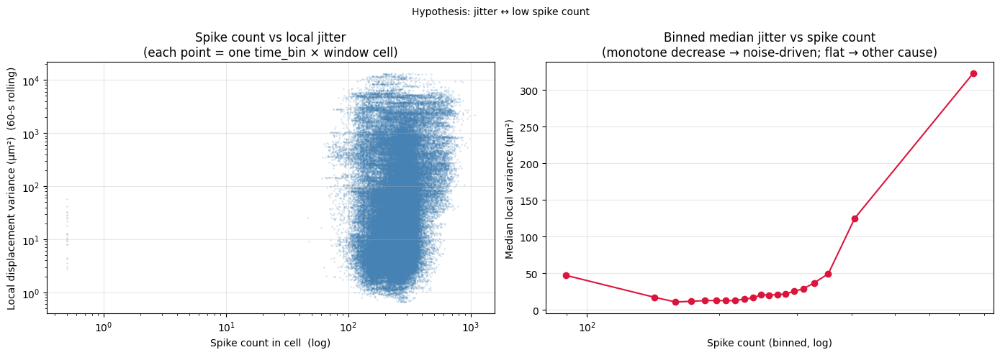

Low-count threshold  : < 117 spikes  →  2005 cells  (1.989%)
High-var threshold   : > 2079.3 µm²  →  5040 cells  (5.0%)
Both (low & high-var): 132 cells

  Time (s)   Win  Depth (µm)   Count   Loc var (µm²)  Note
-----------------------------------------------------------------
    4160.5    23        3635       0            8.06  
    4160.5    22        3485       0            8.17  
    4160.5    20        3185       0           33.07  
    4160.5    17        2735       0           11.95  
    4160.5    19        3035       0           41.81  
    4160.5    18        2885       0           18.04  
    4160.5    21        3335       0           12.73  
    4160.5    16        2585       0           10.28  
    4160.5     2         485       0            3.08  
    4160.5     1         335       0            2.79  
    4160.5     0         185       0            3.61  
    4160.5     4         785       0           56.76  
    4160.5     9        1535       0           10.65  
    41

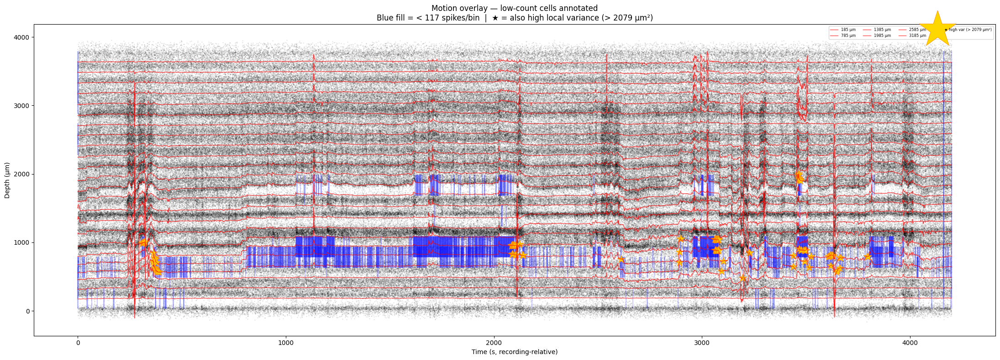

In [9]:
# ── Cell J7: does jitter correlate with low spike count? ─────────────────────
# Local displacement variance is computed from the DREDge *solved* displacement
# (displacement_seg0.npy), not raw spikes.  Specifically: rolling variance over
# ROLL_WIN bins using uniform_filter1d(x²) − uniform_filter1d(x)².

from scipy.ndimage import uniform_filter1d
from matplotlib.patches import Rectangle

ROLL_WIN = 60
local_mean = uniform_filter1d(displacement_j, size=ROLL_WIN, axis=0)
local_mean2 = uniform_filter1d(displacement_j**2, size=ROLL_WIN, axis=0)
local_var_j = local_mean2 - local_mean**2

colors_w = plt.cm.tab20(np.linspace(0, 1, n_win_j))
disp_var_flat  = local_var_j.flatten()
counts_flat_j  = spike_counts_j.flatten()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(counts_flat_j + 0.5, disp_var_flat + 1e-4,
                s=1, alpha=0.15, color='steelblue', rasterized=True)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('Spike count in cell  (log)')
axes[0].set_ylabel(f'Local displacement variance (µm²)  ({ROLL_WIN}-s rolling)')
axes[0].set_title('Spike count vs local jitter\n(each point = one time_bin × window cell)')
axes[0].grid(True, alpha=0.3)

count_percentiles = np.percentile(counts_flat_j[counts_flat_j > 0], np.linspace(0, 100, 21))
count_percentiles = np.unique(count_percentiles)
bin_labels = 0.5 * (count_percentiles[:-1] + count_percentiles[1:])
dig = np.digitize(counts_flat_j, count_percentiles) - 1
dig = np.clip(dig, 0, len(count_percentiles) - 2)
med_var = [np.median(disp_var_flat[dig == i]) for i in range(len(bin_labels))]

axes[1].plot(bin_labels, med_var, 'o-', color='crimson')
axes[1].set_xscale('log')
axes[1].set_xlabel('Spike count (binned, log)')
axes[1].set_ylabel('Median local variance (µm²)')
axes[1].set_title('Binned median jitter vs spike count\n'
                  '(monotone decrease → noise-driven; flat → other cause)')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Hypothesis: jitter ↔ low spike count', fontsize=10)
plt.tight_layout()
fig.savefig(DIAG_SAVE_DIR / 'J7_count_vs_jitter_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Low-count cell inventory ──────────────────────────────────────────────────
LOW_COUNT_THR = max(1, int(np.percentile(spike_counts_j[spike_counts_j > 0], 2)))
HIGH_VAR_THR  = float(np.percentile(local_var_j, 95))

low_count_mask = spike_counts_j < LOW_COUNT_THR
high_var_mask  = local_var_j > HIGH_VAR_THR
both_mask      = low_count_mask & high_var_mask

print(f"Low-count threshold  : < {LOW_COUNT_THR} spikes  →  {low_count_mask.sum()} cells  ({100*low_count_mask.mean():.3f}%)")
print(f"High-var threshold   : > {HIGH_VAR_THR:.1f} µm²  →  {high_var_mask.sum()} cells  ({100*high_var_mask.mean():.1f}%)")
print(f"Both (low & high-var): {both_mask.sum()} cells")
print()

low_t_idx, low_w_idx = np.where(low_count_mask)
order = np.argsort(spike_counts_j[low_t_idx, low_w_idx])
print(f"{'Time (s)':>10}  {'Win':>4}  {'Depth (µm)':>10}  {'Count':>6}  {'Loc var (µm²)':>14}  Note")
print("-" * 65)
for i in order[:60]:
    t_i, w_i = low_t_idx[i], low_w_idx[i]
    note = "★ HIGH VAR" if high_var_mask[t_i, w_i] else ""
    print(f"{t_bins_rel_j[t_i]:10.1f}  {w_i:4d}  {s_bins_j[w_i]:10.0f}  "
          f"{spike_counts_j[t_i, w_i]:6d}  {local_var_j[t_i, w_i]:14.2f}  {note}")
if len(order) > 60:
    print(f"  ... ({len(order) - 60} more low-count cells not shown)")

# ── Motion-overlay plot with rectangles + stars ───────────────────────────────
SUBSAMPLE = 20
pt_sub = pt_j[::SUBSAMPLE]
pd_sub = pd_j[::SUBSAMPLE]

fig2, ax2b = plt.subplots(figsize=(22, 8))
ax2b.scatter(pt_sub, pd_sub, s=0.3, c='k', alpha=0.12, rasterized=True, zorder=1)

for w in range(n_win_j):
    ax2b.plot(t_bins_rel_j, s_bins_j[w] + displacement_j[:, w],
              linewidth=1.0, alpha=0.7, color='red',
              label=f'{int(s_bins_j[w])} µm' if w % 4 == 0 else '', zorder=4)

dt = float(bin_s_j)
dh = half_win_j * 2
for t_i, w_i in zip(low_t_idx, low_w_idx):
    rect = Rectangle((t_bins_rel_j[t_i] - dt / 2, s_bins_j[w_i] - half_win_j),
                     dt, dh,
                     linewidth=1.2, edgecolor='blue', facecolor='cornflowerblue',
                     alpha=0.25, zorder=2)
    ax2b.add_patch(rect)

bt_idx, bw_idx = np.where(both_mask)
if len(bt_idx) > 0:
    ax2b.scatter(t_bins_rel_j[bt_idx],
                 s_bins_j[bw_idx] + displacement_j[bt_idx, bw_idx],
                 marker='*', s=150, color='gold', edgecolors='darkorange',
                 linewidths=0.6, zorder=3,
                 label=f'★ high var (> {HIGH_VAR_THR:.0f} µm²)')

ax2b.set_xlabel('Time (s, recording-relative)')
ax2b.set_ylabel('Depth (µm)')
ax2b.set_title(f'Motion overlay — low-count cells annotated\n'
               f'Blue fill = < {LOW_COUNT_THR} spikes/bin  |  '
               f'★ = also high local variance (> {HIGH_VAR_THR:.0f} µm²)')
ax2b.legend(loc='upper right', fontsize=6, ncol=4, markerscale=5)
plt.tight_layout()
fig2.savefig(DIAG_SAVE_DIR / 'J7_motion_overlay_lowcount.png', dpi=150, bbox_inches='tight')
plt.show()

#### **SECOND-ITERATION DRIFT CORRECTION — apply chunks_combined_linear to all localized peaks**

Peaks: 126,258,007  |  locs: 126,258,007  |  fields: ('x', 'y', 'z', 'alpha')
fs=30000.0 Hz  time_offset=13853.945 s

Using motion: motion_dredge_amp20pct_0000min_0070min  (13854.4 – 18053.4 s)


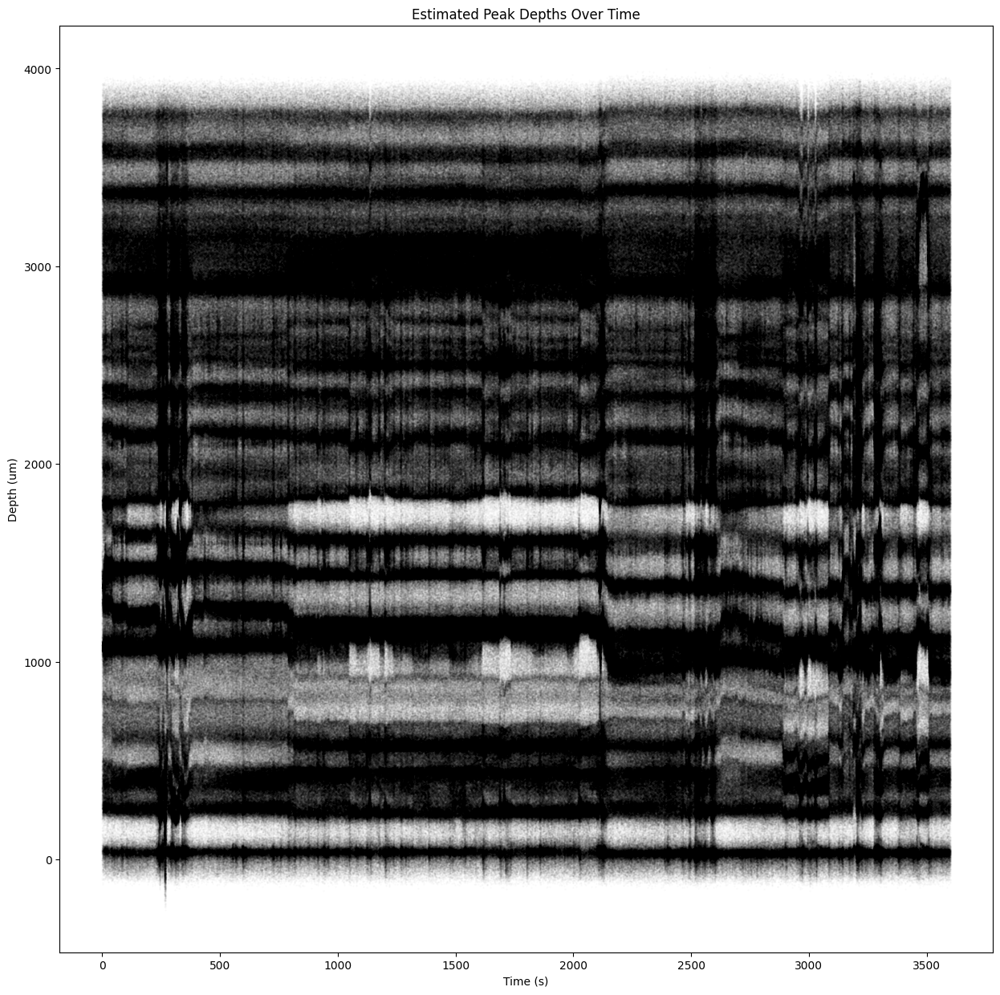


Saved: /ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed/thresholding_peaks_3.3/localized_peaks_mt_n30corrected.npy  shape=(126258007,)
y range (raw):       -620.6 – 3990.1 µm
y range (corrected): -623.8 – 4005.0 µm


In [3]:

import numpy as np
from pathlib import Path
import spikeinterface as si
import matplotlib.pyplot as plt

BASE      = Path('/ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed')
PEAKS_DIR = BASE / 'thresholding_peaks_3.3'
MOTION_DIR = PEAKS_DIR / 'motion_estimates/chunks_n30'
OUT_PATH  = PEAKS_DIR / 'localized_peaks_mt_n30corrected.npy'

# ── load data ────────────────────────────────────────────────────────────────
peaks = np.load(PEAKS_DIR / 'peaks_combined2_sorted.npy')
locs  = np.load(PEAKS_DIR / 'localized_peaks_mt_raw.npy')
print(f"Peaks: {len(peaks):,}  |  locs: {len(locs):,}  |  fields: {locs.dtype.names}")

rec         = si.load(str(BASE))
fs          = rec.get_sampling_frequency()
time_offset = rec.get_times()[0]
print(f"fs={fs} Hz  time_offset={time_offset:.3f} s")

# absolute time for every peak
peak_times_abs = peaks['sample_index'] / fs + time_offset

# ── load first chunk motion only ─────────────────────────────────────────────
motion_folder = sorted(MOTION_DIR.glob('motion_dredge_*'))[0]
motion = si.Motion.load(str(motion_folder))
t0, t1 = motion.temporal_bins_s[0][0], motion.temporal_bins_s[0][-1]
print(f"\nUsing motion: {motion_folder.name}  ({t0:.1f} – {t1:.1f} s)")

# ── apply correction ─────────────────────────────────────────────────────────
depths_raw  = locs['y'].copy()

shifts = motion.get_displacement_at_time_and_depth(
    peak_times_abs,
    depths_raw
)
corrected_y = depths_raw - shifts

plot_drift_scatter(peaks, corrected_y, fs, t_min=0, t_max=3600, save_name=None)

# ── save ─────────────────────────────────────────────────────────────────────
out_locs       = locs.copy()
out_locs['y']  = corrected_y
np.save(str(OUT_PATH), out_locs)
print(f"\nSaved: {OUT_PATH}  shape={out_locs.shape}")
print(f"y range (raw):       {depths_raw.min():.1f} – {depths_raw.max():.1f} µm")
print(f"y range (corrected): {corrected_y.min():.1f} – {corrected_y.max():.1f} µm")
